# Εργασία Μηχανικής Μάθησης: Ανάλυση Δημοπρασιών eBay & CIFAR-10
**Μάθημα:** Μηχανική Μάθηση: Μέθοδοι και Αλγόριθμοι

**Φοιτητής:** Χρήστος Τσάμης

**Αριθμός Μητρώου:** me25038

---

# Εισαγωγή και Βιβλιοθήκες
Σε αυτό το βήμα εισάγουμε τις βιβλιοθήκες. Θα χρειαστούμε:

1. pickle: Για την ανάγνωση των binary αρχείων του CIFAR-10.

2. skimage (scikit-image): Για την εξαγωγή των χαρακτηριστικών HOG.

3. sklearn: Για τους αλγορίθμους SVM, PCA και την αξιολόγηση.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
import pandas as pd

# Βιβλιοθήκες Μηχανικής Μάθησης & Επεξεργασίας Εικόνας
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# HOG Feature Extraction
from skimage.feature import hog
from skimage import color

# Ρυθμίσεις εμφάνισης
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Οι βιβλιοθήκες για το CIFAR-10 φορτώθηκαν.")

Οι βιβλιοθήκες για το CIFAR-10 φορτώθηκαν.


# Ταξινόμηση Εικόνων CIFAR-10 με Κλασικούς Αλγορίθμους

Στην παρούσα εργασία, θα ασχοληθούμε με την αναγνώριση εικόνων από το dataset **CIFAR-10**.
Το dataset αποτελείται από έγχρωμες εικόνες 32x32 pixels που ανήκουν σε 10 κατηγορίες (π.χ. Αεροπλάνο, Αυτοκίνητο, Πουλί, Γάτα, κ.λπ.).

**Η μεθοδολογία μας (Pipeline):**
Αντί να χρησιμοποιήσουμε Νευρωνικά Δίκτυα (Deep Learning), θα εφαρμόσουμε μια κλασική προσέγγιση Μηχανικής Όρασης:
1.  **HOG (Histogram of Oriented Gradients):** Για την εξαγωγή χαρακτηριστικών (σχήματα, ακμές) από τις εικόνες.
2.  **PCA (Principal Component Analysis):** Για τη μείωση των διαστάσεων και την επιτάχυνση της εκπαίδευσης.
3.  **Classification:** Σύγκριση τριών αλγορίθμων:
    * Support Vector Machine (SVM)
    * k-Nearest Neighbors (k-NN)
    * Random Forest

In [ ]:
# Συνάρτηση φόρτωσης ενός batch
def load_cifar_batch(file):
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict[b'data'], dict[b'labels']

# Φάκελος δεδομένων (βεβαιώσου ότι το path είναι σωστό)
cifar10_dir = '/content/drive/MyDrive/Εργασια τελελης /cifar-10-batches-py'

batches_to_load = range(1, 4)

X_train_list = []
y_train_list = []

print(f" Φόρτωση {len(batches_to_load)} batches εκπαίδευσης...")

for i in batches_to_load:
    filename = os.path.join(cifar10_dir, f'data_batch_{i}')
    if os.path.exists(filename):
        print(f"   -> Φόρτωση: {filename}")
        X, y = load_cifar_batch(filename)
        X_train_list.append(X)
        y_train_list.append(y)
    else:
        print(f" Το αρχείο {filename} δεν βρέθηκε!")

# Ένωση όλων των λιστών σε έναν μεγάλο πίνακα
if X_train_list:
    X_train_img = np.vstack(X_train_list)
    y_train = np.hstack(y_train_list)

    # Μετατροπή σε float και αναδιάταξη διαστάσεων για το skimage
    X_train_img = X_train_img.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).astype("float") / 255.0

    print(f"\n Επιτυχία! Νέο μέγεθος Training Set: {X_train_img.shape[0]} εικόνες")
else:
    print(" Δεν φορτώθηκαν δεδομένα.")

# Φόρτωση Test Set (Παραμένει σταθερό 10.000)
test_file = os.path.join(cifar10_dir, 'test_batch')
X_test, y_test = load_cifar_batch(test_file)
X_test_img = X_test.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).astype("float") / 255.0
y_test = np.array(y_test)
print(f" Test Set: {X_test_img.shape[0]} εικόνες")

 Φόρτωση 3 batches εκπαίδευσης...
   -> Φόρτωση: /content/drive/MyDrive/Εργασια τελελης /cifar-10-batches-py/data_batch_1
   -> Φόρτωση: /content/drive/MyDrive/Εργασια τελελης /cifar-10-batches-py/data_batch_2
   -> Φόρτωση: /content/drive/MyDrive/Εργασια τελελης /cifar-10-batches-py/data_batch_3

 Επιτυχία! Νέο μέγεθος Training Set: 30000 εικόνες
 Test Set: 10000 εικόνες


# Επιλογή Υποσυνόλου και Οπτικοποίηση
Για να εξασφαλίσουμε γρήγορη εκτέλεση και να ελέγξουμε την ορθότητα των δεδομένων:

1. Επιλέγουμε ένα υποσύνολο (π.χ. 10.000 εικόνες για Train και 2.000 για Test).

2. Εμφανίζουμε τυχαία δείγματα για να δούμε τι καλούμαστε να αναγνωρίσουμε.

Δεδομένα Εκπαίδευσης: (20000, 32, 32, 3)
Δεδομένα Ελέγχου: (4000, 32, 32, 3)


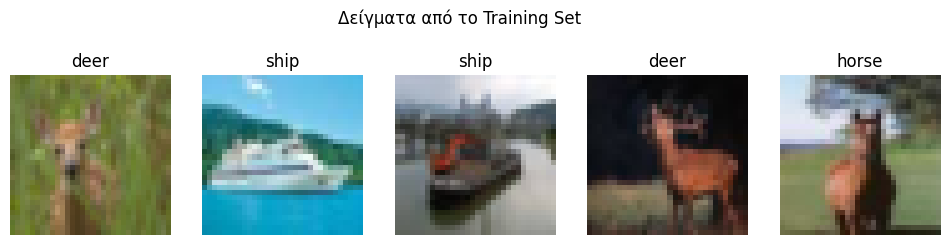

In [ ]:
label_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Combine original train and test data for resampling
X_combined = np.concatenate((X_train_img, X_test_img), axis=0)
y_combined = np.concatenate((y_train, y_test), axis=0)

# Επιλογή υποσυνόλου για γρήγορη εκπαίδευση (Stratified Split)
# Χρησιμοποιούμε 24.000 δείγματα συνολικά για να τρέξει σε λογικό χρόνο
X_train_img, X_test_img, y_train, y_test = train_test_split(
    X_combined, y_combined, train_size=20000, test_size=4000, stratify=y_combined, random_state=15
)

print(f"Δεδομένα Εκπαίδευσης: {X_train_img.shape}")
print(f"Δεδομένα Ελέγχου: {X_test_img.shape}")

# Οπτικοποίηση
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(X_train_img[i])
    ax.set_title(label_names[y_train[i]])
    ax.axis('off')
plt.suptitle("Δείγματα από το Training Set")
plt.show()

## 2. Εξαγωγή Χαρακτηριστικών: HOG vs HOG + Color

Για να διαπιστώσουμε την αξία της χρωματικής πληροφορίας, θα δημιουργήσουμε δύο διαφορετικά σύνολα δεδομένων εκπαίδευσης:

1.  **HOG Only:** Περιέχει μόνο τα χαρακτηριστικά σχήματος/υφής από την ασπρόμαυρη εικόνα.
2.  **HOG + Color:** Περιέχει τα χαρακτηριστικά HOG συνενωμένα με το Ιστόγραμμα Χρώματος (Color Histogram).

Θα εκπαιδεύσουμε τα μοντέλα και στα δύο σύνολα για να συγκρίνουμε την επίδοσή τους.

Η προσθήκη της χρωματικής πληροφορίας κρίνεται σκόπιμη καθώς στο CIFAR-10 πολλές κλάσεις διακρίνονται έντονα από το φόντο ή το χρώμα τους (π.χ. Πλοίο σε μπλε θάλασσα, Βάτραχος σε πράσινο φόντο), πληροφορία που χάνεται με τη μετατροπή σε Grayscale για το HOG.

In [ ]:
# 1. Βοηθητική συνάρτηση για το Χρώμα
def extract_color_histogram(image, bins=32):
    range_max = 1.0 if image.max() <= 1.0 else 255
    hist_r = np.histogram(image[:, :, 0], bins=bins, range=(0, range_max))[0]
    hist_g = np.histogram(image[:, :, 1], bins=bins, range=(0, range_max))[0]
    hist_b = np.histogram(image[:, :, 2], bins=bins, range=(0, range_max))[0]
    # Ενωση και Κανονικοποίηση
    hist = np.hstack((hist_r, hist_g, hist_b))
    hist = hist / (np.sum(hist) + 1e-7)
    return hist

# 2. Κύρια Συνάρτηση Εξαγωγής (Επιστρέφει 2 λίστες)
def extract_features_comparison(images):
    hog_features = []
    combined_features = []
    print(f"Επεξεργασία {len(images)} εικόνων...")

    for img in images:
        # A. HOG (Only)
        gray = color.rgb2gray(img)
        hog_fd = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                     cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        hog_features.append(hog_fd)

        # B. Color
        color_feat = extract_color_histogram(img, bins=32)

        # C. Combined
        combined = np.hstack((hog_fd, color_feat))
        combined_features.append(combined)

    return np.array(hog_features), np.array(combined_features)

# Εφαρμογή: Δημιουργούμε 2 ζευγάρια X_train/X_test
print("--- Training Set ---")
X_train_hog, X_train_comb = extract_features_comparison(X_train_img)

print("\n--- Test Set ---")
X_test_hog, X_test_comb = extract_features_comparison(X_test_img)

print(f"\nΔιαστάσεις HOG Only: {X_train_hog.shape}")
print(f"Διαστάσεις Combined: {X_train_comb.shape}")

--- Training Set ---
Επεξεργασία 20000 εικόνων...

--- Test Set ---
Επεξεργασία 4000 εικόνων...

Διαστάσεις HOG Only: (20000, 324)
Διαστάσεις Combined: (20000, 420)


## 3. Προεπεξεργασία και Μείωση Διαστάσεων (PCA)

Εφαρμόζουμε **StandardScaler** και **PCA** (διατηρώντας το 90% της πληροφορίας) και στα δύο σύνολα δεδομένων (HOG Only και Combined), ώστε η σύγκριση να είναι δίκαιη και τα μοντέλα να εκπαιδευτούν αποδοτικά.

In [ ]:
def preprocess_data(X_train, X_test, variance=0.90):
    # 1. Scaling
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    # 2. PCA
    pca = PCA(n_components=variance)
    X_train_pca = pca.fit_transform(X_train_sc)
    X_test_pca = pca.transform(X_test_sc)

    return X_train_pca, X_test_pca

print(" Προεπεξεργασία HOG Only set...")
X_train_hog_pca, X_test_hog_pca = preprocess_data(X_train_hog, X_test_hog)

print(" Προεπεξεργασία Combined set...")
X_train_comb_pca, X_test_comb_pca = preprocess_data(X_train_comb, X_test_comb)

print("\n Έτοιμα για εκπαίδευση.")
print(f"Features HOG (PCA): {X_train_hog_pca.shape[1]}")
print(f"Features Combined (PCA): {X_train_comb_pca.shape[1]}")

 Προεπεξεργασία HOG Only set...
 Προεπεξεργασία Combined set...

 Έτοιμα για εκπαίδευση.
Features HOG (PCA): 98
Features Combined (PCA): 138


## 4. Μοντέλο 1: SVM - Σύγκριση Επίδοσης

Εκπαιδεύουμε το SVM δύο φορές: μία με τα χαρακτηριστικά HOG και μία με τα συνδυασμένα (HOG + Color).
Στόχος είναι να δούμε αν η προσθήκη του χρώματος βελτιώνει την ικανότητα του SVM να διαχωρίζει τις κλάσεις.

--- 1. SVM: HOG Only ---
Accuracy (HOG Only): 59.58%

--- 2. SVM: HOG + Color ---
Accuracy (Combined): 62.58%


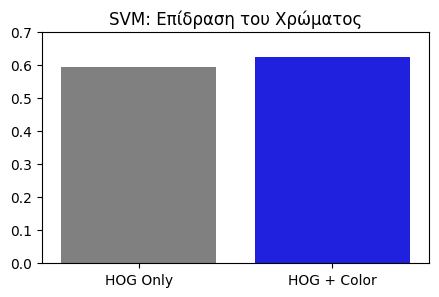

In [ ]:
print("--- 1. SVM: HOG Only ---")
svm_hog = SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced')
svm_hog.fit(X_train_hog_pca, y_train)
acc_svm_hog = accuracy_score(y_test, svm_hog.predict(X_test_hog_pca))
print(f"Accuracy (HOG Only): {acc_svm_hog:.2%}")

print("\n--- 2. SVM: HOG + Color ---")
svm_comb = SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced')
svm_comb.fit(X_train_comb_pca, y_train)
acc_svm_comb = accuracy_score(y_test, svm_comb.predict(X_test_comb_pca))
print(f"Accuracy (Combined): {acc_svm_comb:.2%}")

# Μικρό γράφημα σύγκρισης για το SVM
plt.figure(figsize=(6, 4)) # Μεγάλωσα λίγο το ύψος

# 1. Αποθηκεύουμε το γράφημα στη μεταβλητή 'ax'
ax = sns.barplot(x=['HOG Only', 'HOG + Color'], y=[acc_svm_hog, acc_svm_comb], palette=['gray', 'blue'])

plt.title('SVM: Επίδραση του Χρώματος')
# Αυξάνουμε λίγο το όριο στον άξονα Υ για να χωρέσουν τα γράμματα από πάνω
plt.ylim(0, 0.8)
plt.ylabel('Accuracy')

# 2. Προσθήκη των αριθμών πάνω σε κάθε μπάρα
for p in ax.patches:
    # Παίρνουμε το ύψος της μπάρας (δηλαδή την ακρίβεια)
    height = p.get_height()

    # Προσθέτουμε το κείμενο
    # x: Κέντρο της μπάρας
    # y: Λίγο πιο πάνω από το ύψος της μπάρας (height + 0.01)
    # s: Το string που θα εμφανιστεί (μορφοποίηση σε ποσοστό)
    ax.text(x = p.get_x() + p.get_width()/2,
            y = height + 0.01,
            s = f'{height:.2%}',
            ha = 'center',      # Οριζόντια στοίχιση: Κέντρο
            va = 'bottom',      # Κάθετη στοίχιση: Κάτω (για να πατάει πάνω στη μπάρα)
            fontsize=12,
            fontweight='bold')

plt.show()

### Οπτικοποίηση Αποτελεσμάτων: Confusion Matrix (HOG + Color)

Παρακάτω παραθέτουμε τον πίνακα σύγχυσης (Confusion Matrix) για το βελτιωμένο μοντέλο **SVM (HOG + Color)**.
Μας επιτρέπει να δούμε ποιες κλάσεις μπερδεύει ακόμα το μοντέλο.


=== ΑΝΑΛΥΤΙΚΗ ΑΞΙΟΛΟΓΗΣΗ: SVM με HOG + COLOR ===
Total Accuracy: 62.58%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.67      0.69      0.68       399
  automobile       0.70      0.76      0.73       402
        bird       0.55      0.53      0.54       401
         cat       0.41      0.42      0.42       401
        deer       0.57      0.55      0.56       400
         dog       0.54      0.52      0.53       395
        frog       0.70      0.68      0.69       402
       horse       0.69      0.69      0.69       404
        ship       0.70      0.73      0.71       397
       truck       0.72      0.70      0.71       399

    accuracy                           0.63      4000
   macro avg       0.62      0.63      0.62      4000
weighted avg       0.62      0.63      0.63      4000



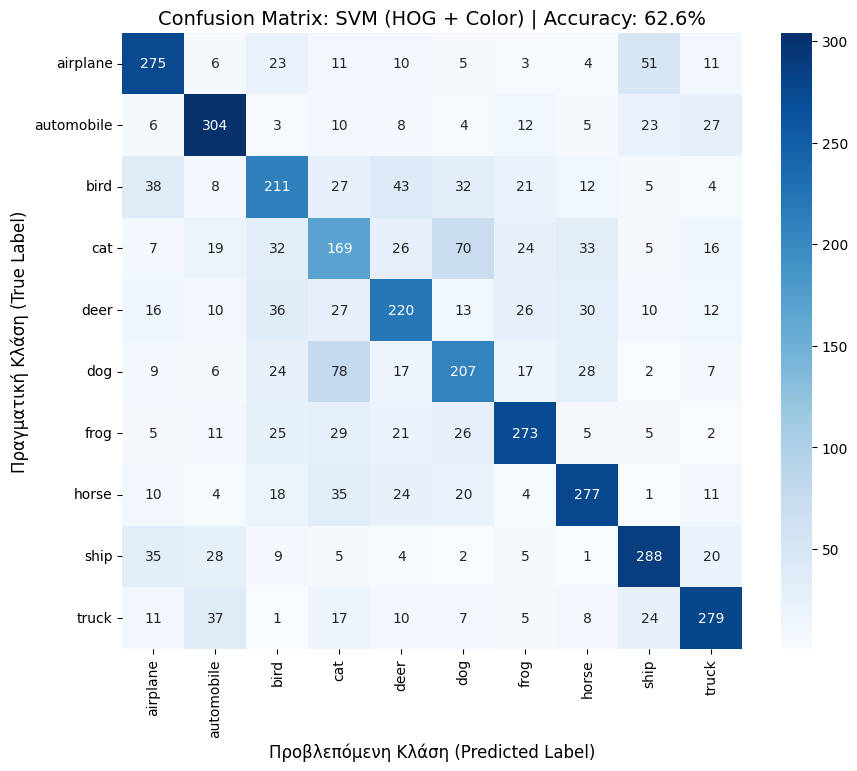

In [ ]:


# 1. Παίρνουμε τις προβλέψεις από το βελτιωμένο μοντέλο (HOG + Color)
y_pred_comb = svm_comb.predict(X_test_comb_pca)

# 2. Εκτύπωση Ακρίβειας & Report
print(f"\n=== ΑΝΑΛΥΤΙΚΗ ΑΞΙΟΛΟΓΗΣΗ: SVM με HOG + COLOR ===")
acc_final = accuracy_score(y_test, y_pred_comb)
print(f"Total Accuracy: {acc_final:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_comb, target_names=label_names))

# 3. Σχεδίαση Confusion Matrix
cm = confusion_matrix(y_test, y_pred_comb)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)

plt.ylabel('Πραγματική Κλάση (True Label)', fontsize=12)
plt.xlabel('Προβλεπόμενη Κλάση (Predicted Label)', fontsize=12)
plt.title(f'Confusion Matrix: SVM (HOG + Color) | Accuracy: {acc_final:.1%}', fontsize=14)
plt.show()

## 5. Μοντέλο 2: k-NN - Σύγκριση Επίδοσης

Ομοίως, εξετάζουμε πώς επηρεάζεται ο αλγόριθμος των k-Εγγύτερων Γειτόνων από την προσθήκη της πληροφορίας χρώματος.

--- 1. k-NN: HOG Only ---
Accuracy (HOG Only): 47.95%

--- 2. k-NN: HOG + Color ---
Accuracy (Combined): 49.62%


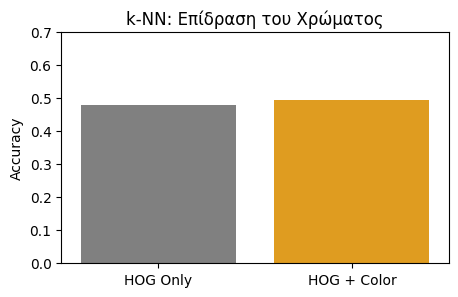

In [ ]:
print("--- 1. k-NN: HOG Only ---")
knn_hog = KNeighborsClassifier(n_neighbors=19, weights='uniform', n_jobs=-1)
knn_hog.fit(X_train_hog_pca, y_train)
acc_knn_hog = accuracy_score(y_test, knn_hog.predict(X_test_hog_pca))
print(f"Accuracy (HOG Only): {acc_knn_hog:.2%}")

print("\n--- 2. k-NN: HOG + Color ---")
knn_comb = KNeighborsClassifier(n_neighbors=19, weights='uniform', n_jobs=-1)
knn_comb.fit(X_train_comb_pca, y_train)
acc_knn_comb = accuracy_score(y_test, knn_comb.predict(X_test_comb_pca))
print(f"Accuracy (Combined): {acc_knn_comb:.2%}")

# Γράφημα σύγκρισης για το k-NN
plt.figure(figsize=(5, 3))
sns.barplot(x=['HOG Only', 'HOG + Color'], y=[acc_knn_hog, acc_knn_comb], palette=['gray', 'orange'])
plt.title('k-NN: Επίδραση του Χρώματος')
plt.ylim(0, 0.7)  # Κρατάμε την ίδια κλίμακα με το SVM για άμεση σύγκριση
plt.ylabel('Accuracy')
plt.show()



  ### Οπτικοποίηση Αποτελεσμάτων: Confusion Matrix (k-NN)

  Παρακάτω βλέπουμε την αναλυτική απόδοση του **k-NN** με χρήση χρωματικής πληροφορίας.
  Στο Confusion Matrix μπορούμε να παρατηρήσουμε αν η προσθήκη χρώματος βοήθησε στη διάκριση κλάσεων που μοιάζουν γεωμετρικά (π.χ. Αυτοκίνητο vs Φορτηγό).


=== ΑΝΑΛΥΤΙΚΗ ΑΞΙΟΛΟΓΗΣΗ: k-NN με HOG + COLOR ===
Total Accuracy: 49.62%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.82      0.45      0.58       399
  automobile       0.54      0.72      0.62       402
        bird       0.74      0.16      0.27       401
         cat       0.45      0.21      0.29       401
        deer       0.36      0.47      0.41       400
         dog       0.49      0.36      0.41       395
        frog       0.35      0.83      0.49       402
       horse       0.70      0.49      0.57       404
        ship       0.60      0.54      0.57       397
       truck       0.51      0.72      0.60       399

    accuracy                           0.50      4000
   macro avg       0.56      0.50      0.48      4000
weighted avg       0.56      0.50      0.48      4000



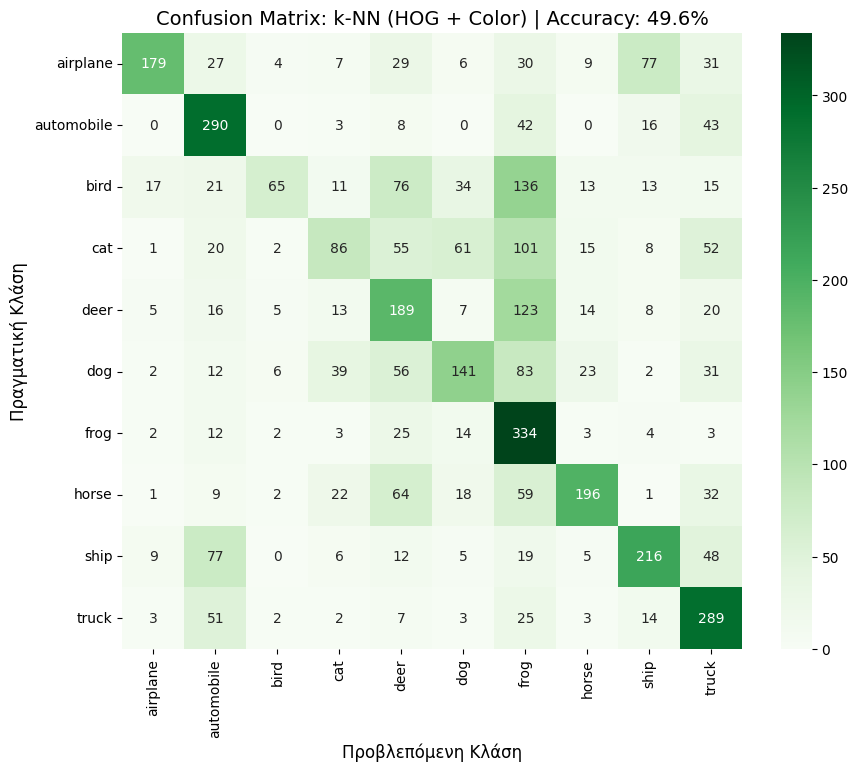

In [ ]:
# 1. Προβλέψεις με το βελτιωμένο k-NN (HOG + Color)
y_pred_knn_comb = knn_comb.predict(X_test_comb_pca)

# 2. Εκτύπωση Ακρίβειας & Report
print(f"\n=== ΑΝΑΛΥΤΙΚΗ ΑΞΙΟΛΟΓΗΣΗ: k-NN με HOG + COLOR ===")
acc_knn_final = accuracy_score(y_test, y_pred_knn_comb)
print(f"Total Accuracy: {acc_knn_final:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn_comb, target_names=label_names))

# 3. Σχεδίαση Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn_comb)

plt.figure(figsize=(10, 8))
# Χρησιμοποιούμε 'Greens' για να ξεχωρίζει οπτικά από το SVM
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens',
            xticklabels=label_names, yticklabels=label_names)

plt.ylabel('Πραγματική Κλάση', fontsize=12)
plt.xlabel('Προβλεπόμενη Κλάση', fontsize=12)
plt.title(f'Confusion Matrix: k-NN (HOG + Color) | Accuracy: {acc_knn_final:.1%}', fontsize=14)
plt.show()

## 6. Μοντέλο 3: Random Forest - Σύγκριση Επίδοσης

Τέλος, συγκρίνουμε την επίδοση του Random Forest.


--- 1. Random Forest: HOG Only ---
Accuracy (HOG Only): 49.12%

--- 2. Random Forest: HOG + Color ---
Accuracy (Combined): 49.50%


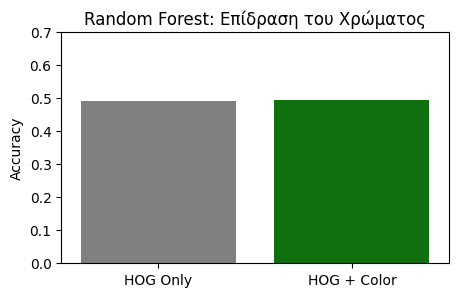

In [ ]:

print("--- 1. Random Forest: HOG Only ---")
rf_hog = RandomForestClassifier(n_estimators=200, max_depth= 20,min_samples_leaf= 4, min_samples_split= 2 , random_state=42, n_jobs=-1)
rf_hog.fit(X_train_hog_pca, y_train)
acc_rf_hog = accuracy_score(y_test, rf_hog.predict(X_test_hog_pca))
print(f"Accuracy (HOG Only): {acc_rf_hog:.2%}")

print("\n--- 2. Random Forest: HOG + Color ---")
rf_comb = RandomForestClassifier(n_estimators=200, max_depth= 20,min_samples_leaf= 4, min_samples_split= 2 , random_state=42, n_jobs=-1)
rf_comb.fit(X_train_comb_pca, y_train)
acc_rf_comb = accuracy_score(y_test, rf_comb.predict(X_test_comb_pca))
print(f"Accuracy (Combined): {acc_rf_comb:.2%}")

# Γράφημα σύγκρισης για το Random Forest
plt.figure(figsize=(5, 3))
sns.barplot(x=['HOG Only', 'HOG + Color'], y=[acc_rf_hog, acc_rf_comb], palette=['gray', 'green'])
plt.title('Random Forest: Επίδραση του Χρώματος')
plt.ylim(0, 0.7)
plt.ylabel('Accuracy')
plt.show()

### Οπτικοποίηση Αποτελεσμάτων: Confusion Matrix (Random Forest)

Τέλος, εξετάζουμε την απόδοση του **Random Forest**.




=== ΑΝΑΛΥΤΙΚΗ ΑΞΙΟΛΟΓΗΣΗ: Random Forest με HOG + COLOR ===
Total Accuracy: 49.50%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.59      0.56      0.58       399
  automobile       0.53      0.65      0.58       402
        bird       0.46      0.29      0.35       401
         cat       0.38      0.21      0.27       401
        deer       0.42      0.40      0.41       400
         dog       0.42      0.50      0.46       395
        frog       0.47      0.62      0.54       402
       horse       0.54      0.52      0.53       404
        ship       0.54      0.62      0.58       397
       truck       0.55      0.57      0.56       399

    accuracy                           0.49      4000
   macro avg       0.49      0.50      0.49      4000
weighted avg       0.49      0.49      0.49      4000



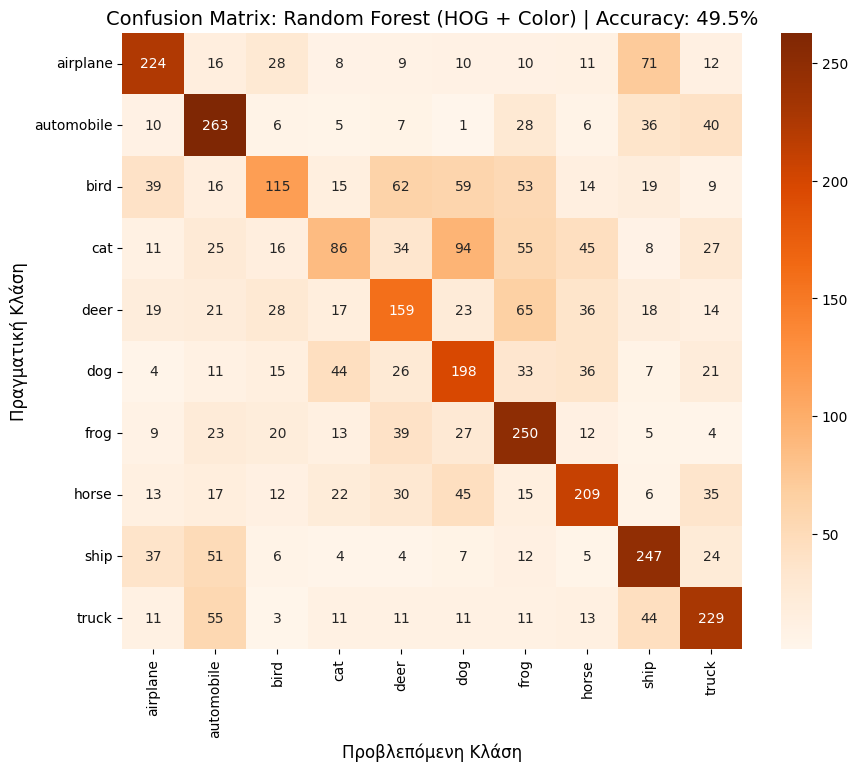

In [ ]:
# 1. Προβλέψεις με το βελτιωμένο Random Forest (HOG + Color)
y_pred_rf_comb = rf_comb.predict(X_test_comb_pca)

# 2. Εκτύπωση Ακρίβειας & Report
print(f"\n=== ΑΝΑΛΥΤΙΚΗ ΑΞΙΟΛΟΓΗΣΗ: Random Forest με HOG + COLOR ===")
acc_rf_final = accuracy_score(y_test, y_pred_rf_comb)
print(f"Total Accuracy: {acc_rf_final:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_comb, target_names=label_names))

# 3. Σχεδίαση Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf_comb)

plt.figure(figsize=(10, 8))
# Χρησιμοποιούμε 'Oranges' για το Random Forest
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges',
            xticklabels=label_names, yticklabels=label_names)

plt.ylabel('Πραγματική Κλάση', fontsize=12)
plt.xlabel('Προβλεπόμενη Κλάση', fontsize=12)
plt.title(f'Confusion Matrix: Random Forest (HOG + Color) | Accuracy: {acc_rf_final:.1%}', fontsize=14)
plt.show()

## 6.1. Πείραμα: Random Forest χωρίς PCA (Raw HOG)

Δοκιμάζουμε να εκπαιδεύσουμε το **Random Forest** απευθείας στα ακατέργαστα χαρακτηριστικά HOG (`X_train_hog`), παρακάμπτοντας το PCA.

**Σκεπτικό:** Ενώ το SVM χρειάζεται το PCA για να αποφύγει την "κατάρα της διαστατικότητας", τα Random Forests έχουν εγγενή μηχανισμό επιλογής χαρακτηριστικών. Συχνά, το PCA "θολώνει" την πληροφορία, οπότε θέλουμε να δούμε αν το μοντέλο τα πηγαίνει καλύτερα με τα πρωτογενή δεδομένα.

In [ ]:

print(" Εκπαίδευση Random Forest ΧΩΡΙΣ PCA (απευθείας στα HOG features)...")
print("(Θα πάρει λίγο περισσότερο χρόνο...)")

# 1. Ορισμός Μοντέλου
rf_no_pca = RandomForestClassifier(n_estimators=200, max_depth= 20 ,min_samples_leaf= 5 , min_samples_split= 2, random_state=42, n_jobs=-1)

# 2. Εκπαίδευση με τα Raw HOG δεδομένα (X_train_hog)
# Σημείωση: Δεν χρειάζεται scaling για Random Forest θεωρητικά
rf_no_pca.fit(X_train_hog, y_train)

# 3. Πρόβλεψη
y_pred_rf_raw = rf_no_pca.predict(X_test_hog)

# 4. Αξιολόγηση
acc_rf_raw = accuracy_score(y_test, y_pred_rf_raw)
print(f"\n Random Forest (No PCA) Accuracy: {acc_rf_raw:.2%}")

# Αναλυτική αναφορά
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_raw, target_names=label_names))

print(" Εκπαίδευση Random Forest ΧΩΡΙΣ PCA (με HOG + Color)...")
# Χρησιμοποιούμε το ίδιο μοντέλο (200 δέντρα)
rf_no_pca_comb = RandomForestClassifier(n_estimators=200, max_depth= 20 ,min_samples_leaf= 4, min_samples_split= 2, random_state=42, n_jobs=-1)

# Εκπαίδευση με τα ΣΥΝΔΥΑΣΜΕΝΑ δεδομένα (X_train_comb)
# Εδώ δεν έχει γίνει PCA, είναι τα raw features (HOG + Color Histograms)
rf_no_pca_comb.fit(X_train_comb, y_train)

# Πρόβλεψη
y_pred_rf_raw_comb = rf_no_pca_comb.predict(X_test_comb)

# Αξιολόγηση
acc_rf_raw_comb = accuracy_score(y_test, y_pred_rf_raw_comb)
print(f"\n Random Forest (No PCA, HOG+Color) Accuracy: {acc_rf_raw_comb:.2%}")


print("\nClassification Report (HOG + Color):")
print(classification_report(y_test, y_pred_rf_raw_comb, target_names=label_names))


 Εκπαίδευση Random Forest ΧΩΡΙΣ PCA (απευθείας στα HOG features)...
(Θα πάρει λίγο περισσότερο χρόνο...)

 Random Forest (No PCA) Accuracy: 50.38%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.59      0.53      0.56       399
  automobile       0.53      0.64      0.58       402
        bird       0.49      0.35      0.41       401
         cat       0.41      0.22      0.29       401
        deer       0.43      0.43      0.43       400
         dog       0.41      0.49      0.44       395
        frog       0.47      0.64      0.54       402
       horse       0.58      0.57      0.57       404
        ship       0.56      0.55      0.55       397
       truck       0.56      0.62      0.59       399

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000

 Εκπαίδευση Random Forest ΧΩΡΙΣ PCA (με HOG + Color)...

 Random Fores

# 7. Τελική Σύγκριση & Συμπεράσματα (Report)
Εδώ συγκρίνουμε τα τρια μοντέλα σε όλες τις περιπτώσεις που αναλύσαμε πιο πάνω


=== ΤΕΛΙΚΟΣ ΣΥΓΚΕΝΤΡΩΤΙΚΟΣ ΠΙΝΑΚΑΣ ===
         Model     Features  Accuracy
0          SVM     HOG Only   0.59575
1          SVM  HOG + Color   0.62575
2         k-NN     HOG Only   0.47950
3         k-NN  HOG + Color   0.49625
4     RF (PCA)     HOG Only   0.49125
5     RF (PCA)  HOG + Color   0.49500
6  RF (No PCA)     HOG Only   0.50375
7  RF (No PCA)  HOG + Color   0.50900


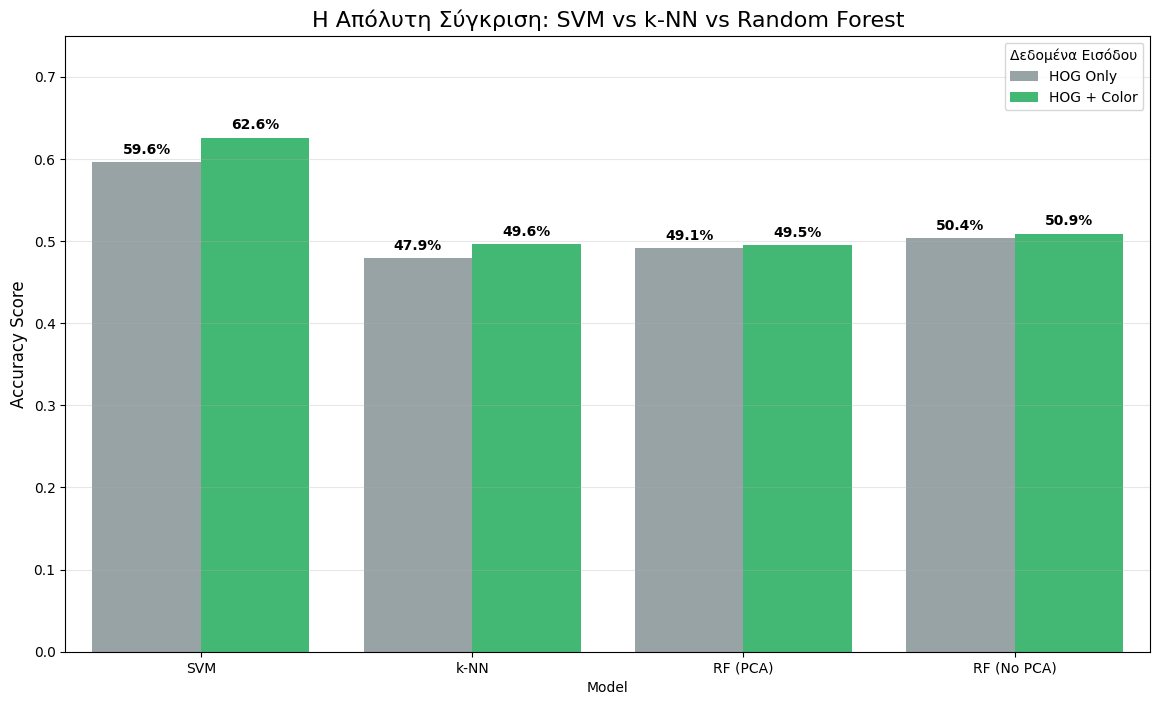

In [ ]:
# Δημιουργία DataFrame με ΟΛΑ τα αποτελέσματα (8 μπάρες σύνολο!)
final_results = pd.DataFrame({
    'Model': [
        'SVM', 'SVM',
        'k-NN', 'k-NN',
        'RF (PCA)', 'RF (PCA)',
        'RF (No PCA)', 'RF (No PCA)' # <-- Τα νέα ζευγάρια
    ],
    'Features': [
        'HOG Only', 'HOG + Color',
        'HOG Only', 'HOG + Color',
        'HOG Only', 'HOG + Color',
        'HOG Only', 'HOG + Color' # <-- Εδώ βάζουμε τα αποτελέσματα χωρίς PCA
    ],
    'Accuracy': [
        acc_svm_hog, acc_svm_comb,
        acc_knn_hog, acc_knn_comb,
        acc_rf_hog, acc_rf_comb,
        acc_rf_raw, acc_rf_raw_comb # <-- Το τελευταίο σκορ που μόλις βρήκαμε
    ]
})

print("=== ΤΕΛΙΚΟΣ ΣΥΓΚΕΝΤΡΩΤΙΚΟΣ ΠΙΝΑΚΑΣ ===")
print(final_results)

# Γράφημα
plt.figure(figsize=(14, 8))
# Χρησιμοποιούμε hue='Features' για να ξεχωρίσουμε το HOG από το HOG+Color
sns.barplot(x='Model', y='Accuracy', hue='Features', data=final_results, palette=['#95a5a6', '#2ecc71'])

plt.title('Η Απόλυτη Σύγκριση: SVM vs k-NN vs Random Forest', fontsize=16)
plt.ylim(0, 0.75)
plt.ylabel('Accuracy Score', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Δεδομένα Εισόδου', loc='upper right')

# Εμφάνιση ποσοστών
for p in plt.gca().patches:
    if p.get_height() > 0: # Αποφεύγουμε κενές μπάρες
        plt.gca().annotate(f'{p.get_height():.1%}',
                           (p.get_x() + p.get_width() / 2., p.get_height()),
                           ha = 'center', va = 'center',
                           xytext = (0, 9),
                           textcoords = 'offset points', fontweight='bold', fontsize=10)

plt.show()

## 8.1 Βελτιστοποίηση Υπερπαραμέτρων SVM (Hyperparameter Tuning)

Στη συνέχεια, βελτιστοποιούμε το μοντέλο **SVM** μέσω της μεθόδου Grid Search. Το SVM είναι πιο "βαρύ" υπολογιστικά, αλλά η σωστή ρύθμιση των παραμέτρων μπορεί να εκτοξεύσει την απόδοσή του.

Ψάχνουμε τον βέλτιστο συνδυασμό για:
* **`C` (Regularization):** Ελέγχει την αυστηρότητα του μοντέλου.
    * *Μεγάλο C:* Αυστηρό μοντέλο (πιθανό Overfitting).
    * *Μικρό C:* Πιο χαλαρό όριο (Underfitting).
* **`gamma` (Kernel Coefficient):** Καθορίζει την εμβέλεια επιρροής κάθε δείγματος.
    * *`scale`:* Αυτόματη προσαρμογή (συνήθως η βέλτιστη).
    * *`0.01`, `0.001`:* Συγκεκριμένες τιμές για έλεγχο ακρίβειας.

In [ ]:
print("\n---  Βελτιστοποίηση SVM (Grid Search) σε HOG + COLOR ---")
print("(Αυτό μπορεί να πάρει λίγη ώρα...)")

# 1. Παράμετροι SVM
param_grid_svm = {
    'C': [1, 10,15,50, 100],            # Πόσο "αυστηρό" είναι το μοντέλο
    'gamma': ['scale', 0.01],     # Εμβέλεια επιρροής
    'kernel': ['rbf']             # Ο πυρήνας που αποδίδει καλύτερα
}

# 2. Grid Search
grid_svm = GridSearchCV(SVC(class_weight='balanced'), param_grid_svm, cv=3, n_jobs=-1, verbose=2)

# Εκπαίδευση στο HOG+Color set (ίσως χρειαστεί να πάρεις subset αν αργεί πολύ, π.χ. [:5000])
grid_svm.fit(X_train_comb_pca, y_train)

# 3. Αποτελέσματα
print(f"\n Βέλτιστες Παράμετροι SVM: {grid_svm.best_params_}")
print(f" Καλύτερη Ακρίβεια (Cross-Val): {grid_svm.best_score_:.2%}")

# 4. Αποθήκευση του "Υπερ-Μοντέλου"
best_svm_comb = grid_svm.best_estimator_


---  Βελτιστοποίηση SVM (Grid Search) σε HOG + COLOR ---
(Αυτό μπορεί να πάρει λίγη ώρα...)
Fitting 3 folds for each of 10 candidates, totalling 30 fits

 Βέλτιστες Παράμετροι SVM: {'C': 15, 'gamma': 'scale', 'kernel': 'rbf'}
 Καλύτερη Ακρίβεια (Cross-Val): 60.72%


## 8.2 Βελτιστοποίηση Υπερπαραμέτρων k-NN (Hyperparameter Tuning)

Η απόδοση του αλγορίθμου **k-Nearest Neighbors (k-NN)** εξαρτάται σημαντικά από τις παραμέτρους του. Εφαρμόζουμε **Grid Search** για να βρούμε τον βέλτιστο συνδυασμό που μεγιστοποιεί την ακρίβεια.

Οι υπερπαράμετροι που εξετάζουμε είναι:
* **`n_neighbors` (k):** Ο αριθμός των γειτόνων.
    * *Μικρό k:* Ευαισθησία στο θόρυβο.
    * *Μεγάλο k:* Πιο ομαλή απόφαση, αλλά κίνδυνος να χαθούν λεπτομέρειες.
* **`weights`:** Η βαρύτητα της ψήφου.
    * *`uniform`:* Ισότιμη ψήφος.
    * *`distance`:* Οι κοντινότεροι γείτονες μετράνε περισσότερο.
* **`metric`:** Ο τρόπος μέτρησης απόστασης (π.χ. **Euclidean** vs **Manhattan**).

In [ ]:

print("\n---  Βελτιστοποίηση k-NN (Grid Search) σε HOG + COLOR ---")

# 1. Ορίζουμε τις παραμέτρους προς εξέταση
param_grid_knn = {
    'n_neighbors': [5,  9, 11, 19],   # Δοκιμάζουμε διάφορους γείτονες
    'weights': ['uniform', 'distance'],    # Ισότιμη vs Σταθμισμένη ψήφος
    'metric' : ['euclidean' , 'manhattan']

}

# 2. Grid Search
# n_jobs=-1: Χρησιμοποιεί όλους τους πυρήνες
# cv=3: 3-fold Cross Validation
grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=3, n_jobs=-1, verbose=1)

print("Εκκίνηση αναζήτησης...")
# ΠΡΟΣΟΧΗ: Εδώ βάζουμε τα δεδομένα HOG+Color (X_train_comb_pca)
grid_knn.fit(X_train_comb_pca, y_train)

# 3. Αποτελέσματα
print(f"\n Βέλτιστες Παράμετροι k-NN: {grid_knn.best_params_}")
print(f" Καλύτερη Ακρίβεια (Cross-Val): {grid_knn.best_score_:.2%}")

# 4. Αξιολόγηση στο Test Set με το καλύτερο μοντέλο
best_knn_comb = grid_knn.best_estimator_
y_pred_knn_opt = best_knn_comb.predict(X_test_comb_pca)

print("\nClassification Report (Optimized k-NN on HOG+Color):")
print(classification_report(y_test, y_pred_knn_opt, target_names=label_names))


---  Βελτιστοποίηση k-NN (Grid Search) σε HOG + COLOR ---
Εκκίνηση αναζήτησης...
Fitting 3 folds for each of 16 candidates, totalling 48 fits

 Βέλτιστες Παράμετροι k-NN: {'metric': 'euclidean', 'n_neighbors': 19, 'weights': 'distance'}
 Καλύτερη Ακρίβεια (Cross-Val): 48.05%

Classification Report (Optimized k-NN on HOG+Color):
              precision    recall  f1-score   support

    airplane       0.83      0.42      0.56       399
  automobile       0.57      0.72      0.64       402
        bird       0.82      0.16      0.27       401
         cat       0.45      0.19      0.27       401
        deer       0.38      0.46      0.42       400
         dog       0.50      0.36      0.42       395
        frog       0.34      0.84      0.48       402
       horse       0.70      0.50      0.58       404
        ship       0.59      0.56      0.58       397
       truck       0.49      0.74      0.59       399

    accuracy                           0.50      4000
   macro avg       

## 8.3. Βελτιστοποίηση Random Forest (HOG + Color χωρίς PCA)

Με βάση τα πειραματικά αποτελέσματα, το **Random Forest** πέτυχε καλύτερη απόδοση όταν εκπαιδεύτηκε στα αρχικά δεδομένα (Raw Features) παρά στα συμπιεσμένα δεδομένα του PCA.

Για τον λόγο αυτό, εφαρμόζουμε τη διαδικασία **Grid Search** απευθείας στο σύνολο **HOG + Color (χωρίς PCA)**.

Στόχος είναι να βρούμε τον βέλτιστο συνδυασμό παραμέτρων που εξισορροπεί την πολυπλοκότητα του μοντέλου και την ικανότητα γενίκευσης:
* **`n_estimators`:** Ο αριθμός των δέντρων (περισσότερα δέντρα = μεγαλύτερη σταθερότητα).
* **`max_depth`:** Το μέγιστο βάθος κάθε δέντρου (έλεγχος για overfitting).
* **`min_samples_split/leaf`:** Περιορισμοί στο πώς μεγαλώνουν τα φύλλα του δέντρου, ώστε να αποφύγουμε την αποστήθιση θορύβου.

In [ ]:
print("\n---  Βελτιστοποίηση Random Forest (Grid Search) σε HOG + COLOR (Χωρίς PCA) ---")
print("(Προσοχή: Η διαδικασία θα είναι χρονοβόρα γιατί τα features είναι πολλά και δεν έχουμε PCA...)")

# 1. Παράμετροι προς δοκιμή
# Μειώσαμε λίγο το εύρος για να μην πάρει ώρες, αλλά κρατήσαμε τις σημαντικές
param_grid_rf = {
    'n_estimators': [100, 200],        # Δοκιμάζουμε 100 και 200 δέντρα
    'max_depth': [None, 20 , 50],           # Βάθος δέντρου: Απεριόριστο , 20 η 50
    'min_samples_split': [2, 4 , 10], # Default=2. Το 5 και 10 μειώνουν το overfitting
    'min_samples_leaf': [1,  4]    # Default=1. Το 2 και 4 "λειαίνουν" το μοντέλο
    }

# 2. Grid Search
# n_jobs=-1: Χρησιμοποιεί όλη τη δύναμη του επεξεργαστή
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42),
                       param_grid_rf,
                       cv=3,
                       n_jobs=-1,
                       verbose=2)

# 3. Εκπαίδευση στο RAW set (HOG + Color ΧΩΡΙΣ PCA)
# ΠΡΟΣΟΧΗ: Χρησιμοποιούμε το X_train_comb (όχι το _pca)
grid_rf.fit(X_train_comb, y_train)

# 4. Αποτελέσματα
print(f"\n Βέλτιστες Παράμετροι RF: {grid_rf.best_params_}")
print(f" Καλύτερη Ακρίβεια (Cross-Val): {grid_rf.best_score_:.2%}")

# 5. Αξιολόγηση στο Test Set
best_rf = grid_rf.best_estimator_
y_pred_rf_opt = best_rf.predict(X_test_comb) # Προσοχή: X_test_comb (όχι _pca)

print("\nClassification Report (Optimized Random Forest - No PCA):")
print(classification_report(y_test, y_pred_rf_opt, target_names=label_names))


---  Βελτιστοποίηση Random Forest (Grid Search) σε HOG + COLOR (Χωρίς PCA) ---
(Προσοχή: Η διαδικασία θα είναι χρονοβόρα γιατί τα features είναι πολλά και δεν έχουμε PCA...)
Fitting 3 folds for each of 36 candidates, totalling 108 fits

 Βέλτιστες Παράμετροι RF: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 200}
 Καλύτερη Ακρίβεια (Cross-Val): 51.15%

Classification Report (Optimized Random Forest - No PCA):
              precision    recall  f1-score   support

    airplane       0.57      0.60      0.58       399
  automobile       0.52      0.64      0.57       402
        bird       0.49      0.33      0.40       401
         cat       0.35      0.21      0.26       401
        deer       0.48      0.47      0.47       400
         dog       0.43      0.50      0.47       395
        frog       0.52      0.61      0.56       402
       horse       0.54      0.54      0.54       404
        ship       0.54      0.53      0.54       397
       tr